# MSH chain on a 2D substrate: spin ramp with TDVP

**Goal.** Evolve the fermion mode through the spin ramp of `msh_substrate_td_python.ipynb` with TDVP on the quantics MPO, and compare
with the exact (sparse-matrix) evolution there at the small sizes, before the scaling scan of the ramp.

**Method.** $\psi_f$ of $H(0)$ from the zero-mode pipeline of `msh_substrate_tn.ipynb` (penalized DMRG, $\hat X$ localization, pairing);
then TensorBinding's `evolve_with_tdvp_timedep`: two-site TDVP with $H$ at the midpoint of each step, $\delta t = 0.1$ (the rule of the
Python notebook, so that the time-step error is common to both), `reverse_step = true`, Krylov tolerance $10^{-12}$ and dimension 30,
the state renormalized after each step. $H(t)$ is `ramp_mpo` (`substrate_model.jl`), the same Hamiltonian as Python's `Ramp.H` to
$10^{-11}$; its exchange profiles are built with `profile_cutoff = 1e-20` (with the static default $10^{-14}$ the rotating texture is off by
up to $5\times10^{-7}$). $\Delta Q$ and $\chi(\psi)$ are recorded at the snapshot times of the Python notebook (`snap_every`).

**Comparison.** The reference is the sparse-matrix evolution of the Python notebook (`expm_multiply` on the sparse $H$, the
same midpoint rule; "sparse" in the tables). At the end, the MPS is contracted to a dense vector in the Python basis; recorded are the infidelities
$1 - |\langle\psi_{\rm sparse}|\psi_{\rm TDVP}\rangle|^2$ at $t = 0$ (DMRG against `eigsh`) and at $t = T$, and the largest difference of
$\Delta Q(t)$ over the snapshots. Needs `data/td_py_psi_*.npz` from the Python notebook (run it first).

**Bond dimension.** At these sizes the MPS has $L_x + L_y + 2 \le 14$ sites, so its largest possible bond dimension is
$2^{\lfloor(L_x+L_y+2)/2\rfloor} \le 128$: with `maxdim` = 256 TDVP truncates only through the SVD `cutoff`. These runs therefore test the
TDVP integrator and the cutoff, not a bond-dimension limit; truncation by `maxdim` matters only on the larger substrates of the scaling scan (sections 5 and 6).

**Contents**
1. Setup
2. The runs
3. SVD cutoff
4. TDVP against the exact evolution
5. TDVP on large substrates
6. Cutoff and bond-dimension cap on large substrates
7. Summary


## 1. Setup

`NPROC` worker processes (one thread each) run the cases in parallel; every worker includes `substrate_model.jl`.

In [ ]:
using Distributed, Printf, DelimitedFiles
const NPROC = 8
nprocs() == 1 && addprocs(NPROC; exeflags = "--project=$(Base.active_project())")
@everywhere include("substrate_model.jl")   # model, ramp_mpo, ramp_duration, snap_every, zero-mode pipeline
@everywhere begin
    using NPZ, Printf
    BLAS.set_num_threads(1)
    const DT = 0.1
    const DATA_DIR = "data"
    const POINTS = Dict("bench" => (P = NamedTuple(), ℓ = 12), "leak" => (P = PC, ℓ = 64))

    "Dense vector of an MPS in the Python basis: index 4n + c, spinor (c↑, c↓, c†↓, −c†↑) (msh_substrate_python.ipynb, section 2)."
    function py_vector(ψ, sites, N)
        v = vec(Array(ITensors.@disable_warn_order(prod(ψ)), reverse(sites)...))     # Julia index nb·2N + σ·N + n
        w = zeros(ComplexF64, 4N)
        for m in 0:N-1
            w[4m+1] = v[m+1]; w[4m+2] = v[N+m+1]; w[4m+3] = v[3N+m+1]; w[4m+4] = -v[2N+m+1]
        end
        return w
    end

    case_name(point, Lx, Ly, rot, maxdim, cutoff) = "$(point)_$(Lx)_$(Ly)_rot$(round(Int, rot))_m$(maxdim)_c$(cutoff)"

    """
        run_case(point, Lx, Ly, rot; maxdim, cutoff) -> (summary NamedTuple, series)

    ψ_f from DMRG, TDVP through the ramp, ΔQ and χ at the snapshots, comparison with the sparse run of the Python notebook. Writes
    data/td_tn_<case>.npz (series and final state) so that finished cases are kept if the notebook stops.
    """
    function run_case(point, Lx, Ly, rot; maxdim=256, cutoff=1e-14)
        P, ℓ = POINTS[point]
        g = Substrate(Lx, Ly, ℓ); N = nsites(g)
        T = ramp_duration(ℓ, rot); n = round(Int, T / DT); every = snap_every(T, DT)
        H0, sites = msh_substrate(g, S_z; P...)
        t_dmrg = @elapsed (z = zero_mode_subspace(H0, sites; xq = xqubits(g)))
        r = fermion_from_subspace(H0, sites, z.ψs, g)
        ψ = r.ψf
        ts, dQ, χ = [0.0], [ΔQ_mode(ψ)], [maxlinkdim(ψ)]
        ψ0 = py_vector(ψ, sites, N)
        s = 0
        t_tdvp = @elapsed while s < n
            k = min(every, n - s); t0 = s * DT
            ψ = last(TB.evolve_with_tdvp_timedep(t -> ramp_mpo(t0 + t, g, rot, sites; P...), ψ, k, DT; maxdim, cutoff,
                                                 tol=1e-12, krylovdim=30, reverse_step=true))
            s += k
            push!(ts, s * DT); push!(dQ, ΔQ_mode(ψ)); push!(χ, maxlinkdim(ψ))
        end
        ψT = py_vector(ψ, sites, N)
        py = npzread(joinpath(DATA_DIR, "td_py_psi_$(point)_$(Lx)_$(Ly)_rot$(round(Int, rot)).npz"))
        @assert py["ts"] ≈ ts
        res = (; point, Lx, Ly, rot_T = rot, T, maxdim, cutoff, chi0 = χ[1], chi_max = maximum(χ), t_dmrg, t_tdvp,
               s_per_step = t_tdvp / n, E_f0 = r.E_f, dQ0 = dQ[1], dQ_T = dQ[end],
               inf0 = 1 - abs2(dot(py["psi0"], ψ0)), infT = 1 - abs2(dot(py["psiT"], ψT)), max_ddQ = maximum(abs.(dQ .- py["dQ"])))
        npzwrite(joinpath(DATA_DIR, "td_tn_" * case_name(point, Lx, Ly, rot, maxdim, cutoff) * ".npz"),
                 Dict("ts" => ts, "dQ" => dQ, "dQ_py" => py["dQ"], "chi" => Float64.(χ), "psiT" => ψT,
                      "summary" => Float64[res.T, res.chi0, res.chi_max, res.t_dmrg, res.t_tdvp, res.s_per_step, res.E_f0, res.dQ0,
                                           res.dQ_T, res.inf0, res.infT, res.max_ddQ]))
        return res
    end
end
println("workers: ", nworkers())

workers: 8


## 2. The runs

Two sets, run together (longest first) on the workers:

- **SVD cutoff** (section 3): leaking point, $128\times8$, $T_{\rm rot} = 100$, `cutoff` = $10^{-10}, 10^{-12}, 10^{-14}, 10^{-20}$ with `maxdim` = 256, and
  `maxdim` = 64 with $10^{-20}$ (64 is the largest bond dimension at this size).
- **All small sizes** (section 4): every (point, size, speed) of the Python notebook with `maxdim` = 256, `cutoff` = $10^{-14}$.

Each finished case is in `data/td_tn_<case>.npz`; cases found there are not run again (`RUN_TDVP = false` only collects). The
collected results go to `td_tn_runs.csv` (one row per case) and `td_tn_dQ.csv` ($\Delta Q$ of both methods and $\chi$ at the
snapshots), both committed. The longest case, $128\times32$ with $T_{\rm rot} = 1600$ ($62\,400$ steps), takes about half a day.

In [ ]:
RUN_TDVP = false   # results are in data/td_tn_*.npz; true reruns missing cases
SIZES = Dict("bench" => [(4, 2), (5, 3), (5, 5)], "leak" => [(7, 1), (7, 3), (7, 5)])
ROTS = Dict("bench" => (10.0, 100.0), "leak" => (100.0, 1600.0))
MAIN = (256, 1e-14)
CUTOFF_SCAN = [(64, 1e-20), (256, 1e-10), (256, 1e-12), (256, 1e-14), (256, 1e-20)]
jobs = unique(vcat([("leak", 7, 3, 100.0, m, c) for (m, c) in CUTOFF_SCAN],
                   [(pt, Lx, Ly, rot, MAIN...) for pt in ("bench", "leak") for (Lx, Ly) in SIZES[pt] for rot in ROTS[pt]]))
sort!(jobs; by = j -> -ramp_duration(POINTS[j[1]].ℓ, j[4]) * 4.0^(j[2] + j[3]))       # rough cost, longest first
npz_of(j) = joinpath(DATA_DIR, "td_tn_" * case_name(j...) * ".npz")
todo = filter(j -> !isfile(npz_of(j)), jobs)
println(length(jobs), " cases, ", length(todo), " to run")
if RUN_TDVP && !isempty(todo)
    pmap(j -> run_case(j[1:4]...; maxdim = j[5], cutoff = j[6]), todo)
end

# collect
cols = ["point", "Lx", "Ly", "rot_T", "maxdim", "cutoff", "T", "chi0", "chi_max", "t_dmrg", "t_tdvp", "s_per_step", "E_f0", "dQ0",
        "dQ_T", "inf0", "infT", "max_ddQ"]
runs = []
open("td_tn_dQ.csv", "w") do io
    println(io, "point,Lx,Ly,rot_T,maxdim,cutoff,t,dQ,dQ_py,chi")
    for j in jobs
        isfile(npz_of(j)) || continue
        d = npzread(npz_of(j))
        push!(runs, Any[j..., d["summary"]...])
        for k in eachindex(d["ts"])
            println(io, join(Any[j..., d["ts"][k], d["dQ"][k], d["dQ_py"][k], Int(d["chi"][k])], ","))
        end
    end
end
open("td_tn_runs.csv", "w") do io
    println(io, join(cols, ","))
    for r in runs; println(io, join(r, ",")); end
end
println(length(runs), " cases collected")

16 cases, 

0 to run
16

 cases collected


## 3. SVD cutoff

Leaking point, $128\times8$ ($D = 4096$, 12 sites, largest bond dimension 64), $T_{\rm rot} = 100$: the infidelity of the final state and
the largest $\Delta Q$ error against the cutoff.

In [ ]:
R = readdlm("td_tn_runs.csv", ','; header = true)[1]
col = Dict(c => i for (i, c) in enumerate(cols))
val(r, c) = r[col[c]]
@printf("%7s %8s | %6s %13s %13s %18s | %8s\n", "maxdim", "cutoff", "χ_max", "1 − F(0)", "1 − F(T)", "max|ΔQ_TN − ΔQ_ex|", "TDVP")
for (m, c) in CUTOFF_SCAN
    i = findfirst(r -> val(r, "point") == "leak" && val(r, "Lx") == 7 && val(r, "Ly") == 3 && val(r, "rot_T") == 100 &&
                       val(r, "maxdim") == m && val(r, "cutoff") == c, collect(eachrow(R)))
    i === nothing && continue
    r = R[i, :]
    @printf("%7d %8.0e | %6d %13.1e %13.1e %18.1e | %7.0fs\n", m, c, val(r, "chi_max"), val(r, "inf0"), val(r, "infT"),
            val(r, "max_ddQ"), val(r, "t_tdvp"))
end

 maxdim   cutoff |  χ_max      1 − F(0)      1 − F(T) max|ΔQ_TN − ΔQ_ex| |     TDVP
     64    1e-20 |     64       7.7e-14       1.0e-11            3.4e-07 |    1017s


    256    1e-10 |     64       7.7e-14       3.0e-07            3.1e-05 |     997s
    256    1e-12 |     64       7.7e-14       2.6e-09            3.2e-06 |    1005s
    256    1e-14 |     64       7.7e-14       2.4e-11            3.7e-07 |    1028s
    256    1e-20 |     64       7.7e-14       1.0e-11            3.4e-07 |    1028s


## 4. TDVP against the exact evolution

All small sizes with `maxdim` = 256, `cutoff` = $10^{-14}$. Columns: the largest bond dimension of $\psi_f(0)$ and over the run (and the
largest possible, $2^{\lfloor(L_x+L_y+2)/2\rfloor}$), the infidelities, the largest $\Delta Q$ difference, $\Delta Q(T)$, and the TDVP time per step
against the sparse time per step of the Python notebook (both measured with several runs sharing the machine). Figure: $|\Delta Q_{\rm TDVP} -
\Delta Q_{\rm exact}|$ along the ramp, and $\chi(t)$.

In [ ]:
kr = readdlm("td_py_runs.csv", ','; header = true)
kcol = Dict(c => i for (i, c) in enumerate(vec(kr[2])))
sparse_ms(pt, Lx, Ly, rot) = (i = findfirst(r -> r[kcol["point"]] == pt && r[kcol["Lx"]] == Lx && r[kcol["Ly"]] == Ly &&
                                             r[kcol["rot_T"]] == rot, collect(eachrow(kr[1]))); kr[1][i, kcol["ms_per_step"]])
@printf("%6s %9s %6s | %4s %5s %5s | %10s %10s %14s %11s | %9s %10s %7s\n", "point", "substrate", "T_rot", "χ₀", "χ_max", "full",
        "1 − F(0)", "1 − F(T)", "max|ΔQ − ex|", "ΔQ(T)", "TDVP/step", "sparse", "ratio")
for r in eachrow(R)
    (val(r, "maxdim"), val(r, "cutoff")) == MAIN || continue
    pt, Lx, Ly, rot = val(r, "point"), Int(val(r, "Lx")), Int(val(r, "Ly")), val(r, "rot_T")
    km = sparse_ms(pt, Lx, Ly, rot)
    @printf("%6s %4d×%-4d %6.0f | %4d %5d %5d | %10.1e %10.1e %14.1e %+11.6f | %8.3fs %8.2fms %7.0f\n", pt, 2^Lx, 2^Ly, rot,
            val(r, "chi0"), val(r, "chi_max"), 2^((Lx + Ly + 2) ÷ 2), val(r, "inf0"), val(r, "infT"), val(r, "max_ddQ"), val(r, "dQ_T"),
            val(r, "s_per_step"), km, 1e3 * val(r, "s_per_step") / km)
end

 point substrate  T_rot |   χ₀ χ_max  full |   1 − F(0)   1 − F(T)   max|ΔQ − ex|       ΔQ(T) | TDVP/step     sparse   ratio
  leak  128×32     1600 |  128   128   128 |    4.6e-14    3.2e-10        6.7e-06   +0.425827 |    0.925s     4.86ms     190


  leak  128×8      1600 |   64    64    64 |    7.7e-14    1.5e-10        2.4e-06   +0.442629 |    0.376s     1.96ms     192
  leak  128×32      100 |  128   128   128 |    4.4e-14    1.2e-10        1.8e-06   -0.231890 |    0.957s     6.26ms     153
  leak  128×8       100 |   64    64    64 |    7.7e-14    2.4e-11        3.7e-07   -0.178402 |    0.263s     2.22ms     119
  leak  128×2      1600 |   31    32    32 |    4.8e-14    8.0e-11        3.1e-06   +0.661688 |    0.157s     1.21ms     130
 bench   32×32      100 |   43    58    64 |    6.6e-14    1.2e-10        2.1e-06   -0.095342 |    0.232s     2.12ms     109
  leak  128×2       100 |   31    32    32 |    4.8e-14    1.4e-11        3.8e-07   +0.014587 |    0.095s     1.28ms      75
 bench   32×32       10 |   43    64    64 |    6.6e-14    5.8e-12        2.4e-07   +0.001600 |    0.265s     2.02ms     132
 bench   32×8       100 |   32    32    32 |    1.7e-14    3.8e-11        1.3e-06   -0.095389 |    0.098s     1.07ms      91


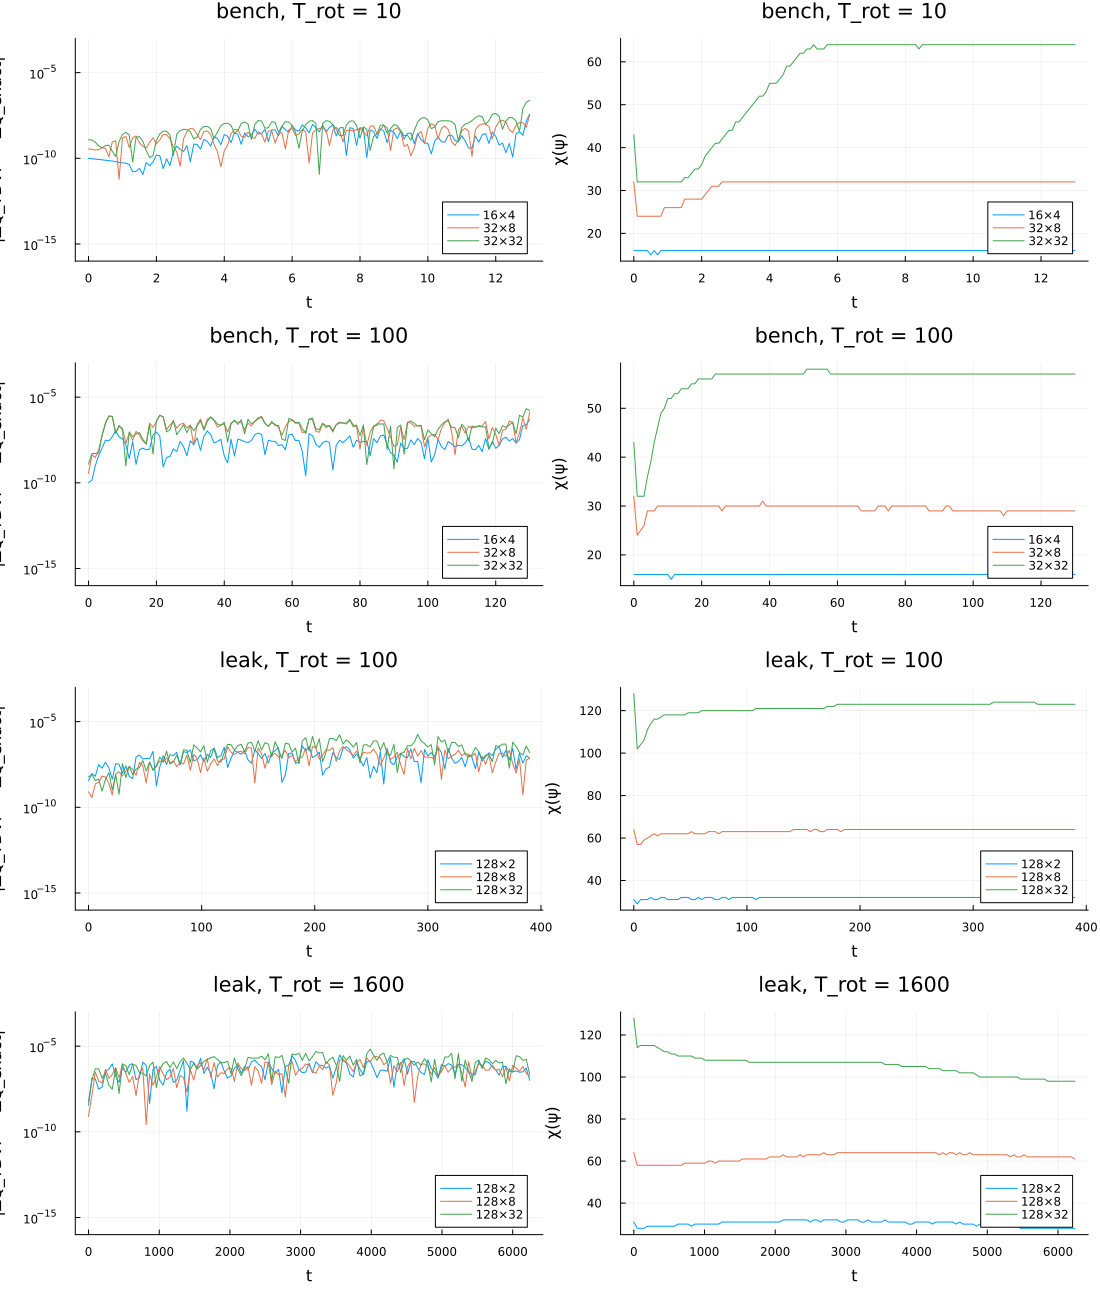

In [ ]:
using Plots
D = readdlm("td_tn_dQ.csv", ','; header = true)[1]
plots = []
for pt in ("bench", "leak"), rot in ROTS[pt]
    p = plot(; yscale = :log10, xlabel = "t", ylabel = "|ΔQ_TDVP − ΔQ_exact|", title = "$pt, T_rot = $(round(Int, rot))",
             legend = :bottomright, ylims = (1e-16, 1e-3))
    q = plot(; xlabel = "t", ylabel = "χ(ψ)", title = "$pt, T_rot = $(round(Int, rot))", legend = :bottomright)
    for (Lx, Ly) in SIZES[pt]
        sel = [D[i, 1] == pt && D[i, 2] == Lx && D[i, 3] == Ly && D[i, 4] == rot && (D[i, 5], D[i, 6]) == MAIN for i in axes(D, 1)]
        any(sel) || continue
        plot!(p, D[sel, 7], max.(abs.(D[sel, 8] .- D[sel, 9]), 1e-16); label = "$(2^Lx)×$(2^Ly)")
        plot!(q, D[sel, 7], D[sel, 10]; label = "$(2^Lx)×$(2^Ly)")
    end
    push!(plots, p, q)
end
plot(plots...; layout = (4, 2), size = (1100, 1300))

## 5. TDVP on large substrates

The scaling scan of the ramp, TN side: the benchmark point on $256^2$ to $2048^2$ sites at both speeds, and the leaking point on $256^2$ and
$512^2$ at $T_{\rm rot} = 100$. The sparse-reference runs of the same cases are in `msh_substrate_td_python.ipynb`, section 7 ($256^2$ to $1024^2$, and
the cost of one step at $2048^2$).

`run_large` is `run_case` without the dense comparison during the run. After the ramp it builds the final pair from the zero-mode
pipeline on $H(T)$ and computes the readouts of the Python notebook: $p_\pm$, the leak and the Majorana matrix $M$ (both pairs from
`mps_majoranas`, the convention of `majorana_matrix` in `substrate_model.py`). Each run writes `data/td_tn_large_<case>.npz` (series and
summary) and `data/td_tn_large_<case>.jls` (final MPS and sites).

Here the MPS has $2L + 2 = 18$ to 24 sites, so it is no longer full rank, and both truncations act: the SVD `cutoff` and the cap
`maxdim` = $\chi_{\max}$. The runs (one process each, about 18 at a time on the machine):

- **Scaling, cutoff $10^{-14}$.** Benchmark point, $L = 8$ to 11, both speeds, $\chi_{\max} = 256$; leaking point, $L = 8, 9$, $\chi_{\max} = 64$ and
  128. The leaking-point runs with $\chi_{\max} = 256$ on $256^2$ and $512^2$ and with 128 on $1024^2$ were stopped after 16 hours without a
  result, once section 6 had shown that the readouts do not need them.
- **Cutoff scan** (section 6). Benchmark point, $512^2$, $T_{\rm rot} = 100$, $\chi_{\max} = 512$, cutoff $10^{-6}$ to $10^{-12}$; leaking point, $256^2$,
  $T_{\rm rot} = 100$, $\chi_{\max} = 256$, the same cutoffs.

The runs took up to 16 hours each, so they were made outside the notebook (the same code with one worker, `RUN_LARGE = false` here only
collects). The collection contracts each final MPS to a dense vector and computes $1 - F = 1 - |\langle\psi_{\rm sparse}|\psi_{\rm TDVP}\rangle|^2$
where a sparse-reference state exists, on the workers, and keeps it in `td_tn_large.csv` (one row per run, committed); $\Delta Q(t)$ and $\chi(t)$ go
to `td_tn_large_series.csv`.

Note on $\chi$: the summary of a run records the largest bond dimension including the initial state, which is the DMRG state (43 at the
benchmark point, 211 to 214 at the leaking point). The tables below show both: $\chi_0$ of $\psi_f(0)$ and $\chi_{\rm run}$, the largest over
the TDVP snapshots ($t > 0$).

In [ ]:
@everywhere begin
    using Serialization
    "Majoranas (γ₁, γ₂) = ((ψ + Cψ)/√2, i(ψ − Cψ)/√2) of an MPS fermion mode (Cconj from substrate_model.jl)."
    mps_majoranas(ψ; cutoff=1e-14) = (c = Cconj(ψ); (+(ψ, c; cutoff) / sqrt(2), +(im * ψ, -im * c; cutoff) / sqrt(2)))

    """
        run_large(point, L, rot; maxdim, cutoff, progress) -> summary vector

    As run_case on the L × L substrate (2^L × 2^L sites), without the dense comparison. After the ramp: the final pair from the
    zero-mode pipeline on H(T), its weights p± on ψ(T), the leak and the Majorana matrix M. Writes data/td_tn_large_<case>.npz
    (ts, dQ, chi, t_wall, summary) and data/td_tn_large_<case>.jls (final MPS and sites). `progress = true` prints t, χ and ΔQ at
    every snapshot. Summary: T, χ₀, χ_max (initial state included), t_dmrg0, t_tdvp, s/step, E_f(0), ΔQ(0), ΔQ(T), t_dmrgT, E_f(T),
    gap(T), p₊, p₋, leak, det M, max|Im M|, ΔQ₊(T).
    """
    function run_large(point, L, rot; maxdim=256, cutoff=1e-14, progress=false)
        P, ℓ = POINTS[point]
        g = Substrate(L, L, ℓ)
        T = ramp_duration(ℓ, rot); n = round(Int, T / DT); every = snap_every(T, DT)
        H0, sites = msh_substrate(g, S_z; P...)
        t_dmrg0 = @elapsed (z = zero_mode_subspace(H0, sites; xq = xqubits(g)))
        r = fermion_from_subspace(H0, sites, z.ψs, g)
        ψ = r.ψf
        ts, dQ, χ, tw = [0.0], [ΔQ_mode(ψ)], [maxlinkdim(ψ)], [0.0]
        s = 0; t_start = time()
        t_tdvp = @elapsed while s < n
            k = min(every, n - s); t0 = s * DT
            ψ = last(TB.evolve_with_tdvp_timedep(t -> ramp_mpo(t0 + t, g, rot, sites; P...), ψ, k, DT; maxdim, cutoff,
                                                 tol=1e-12, krylovdim=30, reverse_step=true))
            s += k
            push!(ts, s * DT); push!(dQ, ΔQ_mode(ψ)); push!(χ, maxlinkdim(ψ)); push!(tw, time() - t_start)
            progress && (@printf("t = %7.1f / %.0f  χ = %3d  ΔQ = %+.6e  TDVP %6.0f s\n", s * DT, T, χ[end], dQ[end], tw[end]); flush(stdout))
        end
        HT = ramp_mpo(T, g, rot, sites; P...)
        t_dmrgT = @elapsed (zT = zero_mode_subspace(HT, sites; xq = xqubits(g)))
        rT = fermion_from_subspace(HT, sites, zT.ψs, g)
        pp, pm = abs2(inner(rT.ψf, ψ)), abs2(inner(Cconj(rT.ψf), ψ))
        M = [inner(a, b) for a in mps_majoranas(rT.ψf), b in mps_majoranas(ψ)]   # both pairs with the same convention (as in Python)
        name = "td_tn_large_" * case_name(point, L, L, rot, maxdim, cutoff)
        serialize(joinpath(DATA_DIR, name * ".jls"), (; ψ, sites))
        summary = Float64[T, χ[1], maximum(χ), t_dmrg0, t_tdvp, t_tdvp / n, r.E_f, dQ[1], dQ[end], t_dmrgT, rT.E_f, zT.E_gap,
                          pp, pm, 1 - pp - pm, real(det(M)), maximum(abs.(imag.(M))), ΔQ_mode(rT.ψf)]
        npzwrite(joinpath(DATA_DIR, name * ".npz"), Dict("ts" => ts, "dQ" => dQ, "chi" => Float64.(χ), "t_wall" => tw, "summary" => summary))
        return summary
    end

    "1 − |⟨ψ_sparse|ψ_TDVP⟩|² of a finished large run against the sparse final state of the Python notebook (NaN if there is none)."
    function large_infidelity(point, L, rot, name)
        kf = joinpath(DATA_DIR, "td_py_psi_$(point)_$(L)_$(L)_rot$(round(Int, rot)).npz")
        isfile(kf) || return NaN
        d = deserialize(joinpath(DATA_DIR, name * ".jls"))
        w = py_vector(d.ψ, d.sites, 4^L); k = npzread(kf)["psiT"]
        return 1 - abs2(dot(k, w)) / (sum(abs2, k) * sum(abs2, w))
    end
end

RUN_LARGE = false
LARGE_JOBS = vcat([("bench", L, rot, 256, 1e-14) for L in 8:11 for rot in (10.0, 100.0)],
                  [("leak", L, 100.0, m, 1e-14) for L in (8, 9) for m in (64, 128)],
                  [("bench", 9, 100.0, 512, c) for c in (1e-6, 1e-8, 1e-10, 1e-12)],
                  [("leak", 8, 100.0, 256, c) for c in (1e-6, 1e-8, 1e-10, 1e-12)])
large_name(j) = "td_tn_large_" * case_name(j[1], j[2], j[2], j[3], j[4], j[5])
large_npz(j) = joinpath(DATA_DIR, large_name(j) * ".npz")
todo = filter(j -> !isfile(large_npz(j)), LARGE_JOBS)
println(length(LARGE_JOBS), " cases, ", length(todo), " not run: ", join(large_name.(todo), ", "))
if RUN_LARGE && !isempty(todo)
    pmap(j -> run_large(j[1], j[2], j[3]; maxdim = j[4], cutoff = j[5]), todo)
end

# collect: summary row per run (1 − F computed once and kept in td_tn_large.csv), ΔQ(t) and χ(t) per run
large_file = "td_tn_large.csv"
large_cols = ["point", "L", "rot_T", "maxdim", "cutoff", "T", "chi0", "chi_run", "t_tdvp", "s_per_step", "dQ_T", "p_plus", "p_minus",
              "leak", "detM", "maxImM", "infT"]
old_inf = Dict{String, Float64}()
if isfile(large_file)
    A = readdlm(large_file, ','; header = true)[1]
    for r in eachrow(A)
        old_inf[large_name((String(r[1]), Int(r[2]), Float64(r[3]), Int(r[4]), Float64(r[5])))] = Float64(r[end])
    end
end
done_jobs = filter(j -> isfile(large_npz(j)), LARGE_JOBS)
need = filter(j -> !haskey(old_inf, large_name(j)), done_jobs)
need_names = large_name.(need)                       # names on the master (large_name is not defined on the workers)
for (j, x) in zip(need, pmap((j, nm) -> large_infidelity(j[1], j[2], j[3], nm), need, need_names))
    old_inf[large_name(j)] = x
end
open(large_file, "w") do io
    println(io, join(large_cols, ","))
    for j in done_jobs
        d = npzread(large_npz(j)); s = d["summary"]
        println(io, join(Any[j..., s[1], Int(s[2]), Int(maximum(d["chi"][2:end])), s[5], s[6], s[9], s[13], s[14], s[15], s[16], s[17],
                             old_inf[large_name(j)]], ","))
    end
end
open("td_tn_large_series.csv", "w") do io
    println(io, "point,L,rot_T,maxdim,cutoff,t,dQ,chi")
    for j in done_jobs
        d = npzread(large_npz(j))
        for k in eachindex(d["ts"]); println(io, join(Any[j..., d["ts"][k], d["dQ"][k], Int(d["chi"][k])], ",")); end
    end
end
println(length(done_jobs), " runs collected, 1 − F computed for ", length(need))

20 cases, 

0 not run: 


20 runs collected, 1 − F computed for 

1


### 5.1 Cost and accuracy against the sparse reference

Cutoff $10^{-14}$. Columns: $\chi_0$ and $\chi_{\rm run}$ (see above), the TDVP time per step and the sparse time per step of the Python
notebook (one run per process, with up to about 18 runs sharing the machine), the leak and $\det M$ of both methods, and the infidelity of
the final state. The sparse cost at $2048^2$ is the measured step time of `td_py_step2048.csv`. These times were measured with up to about 18 runs
sharing the machine; section 6.1 compares both methods on the idle machine.

In [ ]:
L_ = readdlm(large_file, ','; header = true); LG = L_[1]; lcol = Dict(c => i for (i, c) in enumerate(vec(L_[2])))
lv(r, c) = r[lcol[c]]
K_ = readdlm("td_py_large.csv", ','; header = true); KG = K_[1]; kc = Dict(c => i for (i, c) in enumerate(vec(K_[2])))
S_ = readdlm("td_py_step2048.csv", ','; header = true); SG = S_[1]; sc = Dict(c => i for (i, c) in enumerate(vec(S_[2])))
"Sparse-reference row of the Python notebook for (point, L, rot): (s per step, leak, det M); 2048² from the step timing (no readouts)."
function sparse_large(pt, L, rot)
    i = findfirst(r -> r[kc["point"]] == pt && r[kc["Lx"]] == L && r[kc["rot_T"]] == rot, collect(eachrow(KG)))
    i !== nothing && return (KG[i, kc["ms_per_step"]] / 1e3, KG[i, kc["leak"]], KG[i, kc["detM"]])
    i = findfirst(r -> r[sc["point"]] == pt && r[sc["L"]] == L, collect(eachrow(SG)))
    return i === nothing ? (NaN, NaN, NaN) : (SG[i, sc["ms_step"]] / 1e3, NaN, NaN)
end
@printf("%6s %11s %6s %5s | %4s %6s | %10s %10s %7s | %10s %10s | %8s %8s | %9s\n", "point", "substrate", "T_rot", "χmax", "χ₀", "χ_run",
        "TDVP/step", "sparse", "ratio", "leak", "sparse", "det M", "sparse", "1 − F")
for r in sort(collect(eachrow(LG)); by = r -> (lv(r, "point"), lv(r, "maxdim"), lv(r, "rot_T"), lv(r, "L")))
    lv(r, "cutoff") == 1e-14 || continue
    pt, L, rot = lv(r, "point"), Int(lv(r, "L")), lv(r, "rot_T")
    ks, kl, kd = sparse_large(pt, L, rot)
    @printf("%6s %5d×%-5d %6.0f %5d | %4d %6d | %9.2fs %9.2fs %7.2f | %10.3e %10.3e | %+8.4f %+8.4f | %9.1e\n", pt, 2^L, 2^L, rot,
            lv(r, "maxdim"), lv(r, "chi0"), lv(r, "chi_run"), lv(r, "s_per_step"), ks, lv(r, "s_per_step") / ks, lv(r, "leak"), kl,
            lv(r, "detM"), kd, lv(r, "infT"))
end

 point   substrate  T_rot  χmax |   χ₀  χ_run |  TDVP/step     sparse   ratio |       leak     sparse |    det M   sparse |     1 − F
 bench   256×256       10   256 |   43    126 |      3.00s      0.58s    5.19 |  5.317e-01  5.317e-01 |  -0.4683  -0.4683 |   2.5e-07


 bench   512×512       10   256 |   43     74 |      2.33s      2.62s    0.89 |  5.317e-01  5.317e-01 |  -0.4683  -0.4683 |   3.7e-07
 bench  1024×1024      10   256 |   43     74 |      1.42s     10.29s    0.14 |  5.317e-01  5.317e-01 |  -0.4683  -0.4683 |   3.9e-07
 bench  2048×2048      10   256 |   43     76 |      2.62s     22.19s    0.12 |  5.317e-01        NaN |  -0.4683     +NaN |       NaN
 bench   256×256      100   256 |   43    256 |     15.93s      0.48s   33.47 |  4.508e-07  4.728e-07 |  -1.0000  -1.0000 |   9.6e-09
 bench   512×512      100   256 |   43    256 |     24.20s      2.14s   11.31 |  5.056e-07  4.728e-07 |  -1.0000  -1.0000 |   4.6e-08
 bench  1024×1024     100   256 |   43    256 |     29.01s     11.40s    2.54 |  7.549e-07  4.728e-07 |  -1.0000  -1.0000 |   1.8e-07
 bench  2048×2048     100   256 |   43    200 |     10.51s     22.19s    0.47 |  1.505e-06        NaN |  -1.0000     +NaN |       NaN
  leak   256×256      100    64 |  214     64 |      4.19s    

## 6. Cutoff and bond-dimension cap on large substrates

Which truncation the readouts need, where the MPS is not full rank: the cutoff scan of section 5 and the leaking-point runs with
$\chi_{\max} = 64$ and 128, against the same sparse-reference states. Left: $\chi(t)$ of the benchmark scan; middle: of the leaking-point runs; right:
the time per step against the substrate size for TDVP (cutoff $10^{-14}$, and $10^{-12}$ where run) and the sparse reference.

In [ ]:
@printf("%6s %9s | %5s %8s | %4s %6s | %10s | %10s %10s | %8s | %9s\n", "point", "substrate", "χmax", "cutoff", "χ₀", "χ_run",
        "TDVP/step", "leak", "sparse", "det M", "1 − F")
for (pt, L) in (("bench", 9), ("leak", 8))
    ks, kl, kd = sparse_large(pt, L, 100.0)
    for r in sort(collect(eachrow(LG)); by = r -> (-lv(r, "cutoff"), lv(r, "maxdim")))
        (lv(r, "point"), lv(r, "L"), lv(r, "rot_T")) == (pt, L, 100.0) || continue
        @printf("%6s %4d×%-4d | %5d %8.0e | %4d %6d | %9.2fs | %10.3e %10.3e | %+8.4f | %9.1e\n", pt, 2^L, 2^L, lv(r, "maxdim"),
                lv(r, "cutoff"), lv(r, "chi0"), lv(r, "chi_run"), lv(r, "s_per_step"), lv(r, "leak"), kl, lv(r, "detM"), lv(r, "infT"))
    end
    @printf("%6s %4d×%-4d | %16s | %11s | %9.2fs | %10s %10.3e | %+8.4f |\n", pt, 2^L, 2^L, "sparse", "", ks, "", kl, kd)
end

 point substrate |  χmax   cutoff |   χ₀  χ_run |  TDVP/step |       leak     sparse |    det M |     1 − F
 bench  512×512  |   512    1e-06 |   43     32 |      0.37s |  5.298e-03  4.728e-07 |  -0.9947 |   5.3e-03


 bench  512×512  |   512    1e-08 |   43     62 |      0.53s |  3.411e-04  4.728e-07 |  -0.9997 |   3.4e-04
 bench  512×512  |   512    1e-10 |   43     31 |      0.44s |  8.677e-07  4.728e-07 |  -1.0000 |   4.0e-07
 bench  512×512  |   512    1e-12 |   43     48 |      0.61s |  5.105e-07  4.728e-07 |  -1.0000 |   5.0e-08
 bench  512×512  |   256    1e-14 |   43    256 |     24.20s |  5.056e-07  4.728e-07 |  -1.0000 |   4.6e-08
 bench  512×512  |           sparse |             |      2.14s |             4.728e-07 |  -1.0000 |
  leak  256×256  |   256    1e-06 |  214    117 |      1.86s |  9.073e-01  9.082e-01 |  -0.0927 |   2.1e-03


  leak  256×256  |   256    1e-08 |  214    117 |      2.46s |  9.083e-01  9.082e-01 |  -0.0917 |   3.3e-05
  leak  256×256  |   256    1e-10 |  214    144 |      3.98s |  9.082e-01  9.082e-01 |  -0.0918 |   1.8e-06
  leak  256×256  |   256    1e-12 |  214    256 |      8.69s |  9.082e-01  9.082e-01 |  -0.0918 |   9.5e-07
  leak  256×256  |    64    1e-14 |  214     64 |      4.19s |  9.076e-01  9.082e-01 |  -0.0924 |   2.3e-03
  leak  256×256  |   128    1e-14 |  214    128 |      9.71s |  9.082e-01  9.082e-01 |  -0.0918 |   1.2e-06
  leak  256×256  |           sparse |             |      0.45s |             9.082e-01 |  -0.0918 |


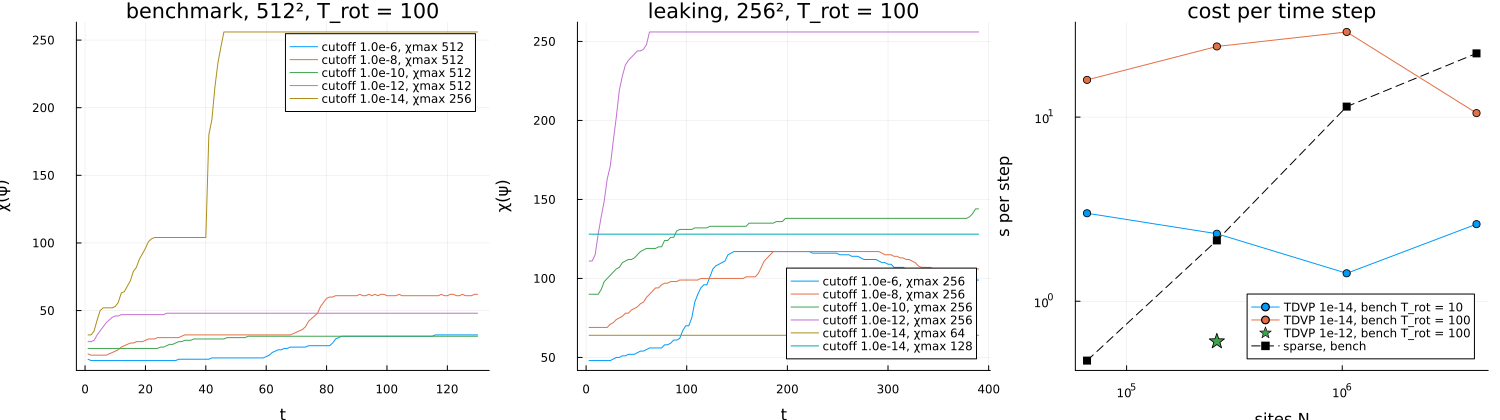

In [ ]:
using Plots
SR = readdlm("td_tn_large_series.csv", ','; header = true)[1]
series(pt, L, rot, m, c) = (sel = [SR[i, 1] == pt && SR[i, 2] == L && SR[i, 3] == rot && SR[i, 4] == m && SR[i, 5] == c for i in axes(SR, 1)];
                            (SR[sel, 6], SR[sel, 8]))
p1 = plot(; xlabel = "t", ylabel = "χ(ψ)", title = "benchmark, 512², T_rot = 100", legend = :topright)
for (m, c) in ((512, 1e-6), (512, 1e-8), (512, 1e-10), (512, 1e-12), (256, 1e-14))
    t, χ = series("bench", 9, 100.0, m, c); isempty(t) || plot!(p1, t[2:end], χ[2:end]; label = "cutoff $c, χmax $m")
end
p2 = plot(; xlabel = "t", ylabel = "χ(ψ)", title = "leaking, 256², T_rot = 100", legend = :bottomright)
for (m, c) in ((256, 1e-6), (256, 1e-8), (256, 1e-10), (256, 1e-12), (64, 1e-14), (128, 1e-14))
    t, χ = series("leak", 8, 100.0, m, c); isempty(t) || plot!(p2, t[2:end], χ[2:end]; label = "cutoff $c, χmax $m")
end
p3 = plot(; xscale = :log10, yscale = :log10, xlabel = "sites N", ylabel = "s per step", title = "cost per time step", legend = :bottomright)
for rot in (10.0, 100.0)
    rs = sort(filter(r -> lv(r, "point") == "bench" && lv(r, "rot_T") == rot && lv(r, "cutoff") == 1e-14, collect(eachrow(LG))); by = r -> lv(r, "L"))
    plot!(p3, [4.0^lv(r, "L") for r in rs], [lv(r, "s_per_step") for r in rs]; marker = :circle, label = "TDVP 1e-14, bench T_rot = $(round(Int, rot))")
end
r12 = filter(r -> lv(r, "point") == "bench" && lv(r, "cutoff") == 1e-12, collect(eachrow(LG)))
isempty(r12) || scatter!(p3, [4.0^lv(r, "L") for r in r12], [lv(r, "s_per_step") for r in r12]; marker = :star5, ms = 8,
                         label = "TDVP 1e-12, bench T_rot = 100")
Lk = 8:11
plot!(p3, 4.0 .^ Lk, [sparse_large("bench", L, 100.0)[1] for L in Lk]; marker = :square, ls = :dash, color = :black, label = "sparse, bench")
plot(p1, p2, p3; layout = (1, 3), size = (1500, 420), left_margin = 5Plots.mm, bottom_margin = 5Plots.mm)

### 6.1 Step times on the idle machine

The times per step of sections 5 and 6 were measured with up to about 18 runs sharing the machine, which slowed TDVP 1.6–4.2 times and
the sparse reference 2.3–4.7 times, not by the same factor. Here both are timed with nothing else running: one TDVP step (with the $H(t)$ rebuild) at
mid-ramp from the final state of each run, the median of 3 after a first one, and the sparse step of `msh_substrate_td_python.ipynb`,
section 7.1. The TDVP time depends on the bond dimension of the state, so it is that of the final state ($\chi_{\rm state}$); for the
benchmark runs with cutoff $10^{-14}$ at $T_{\rm rot} = 100$ this is the cap (256) reached in mid-ramp, so their idle time is an upper bound
for the average step. Results to `td_tn_step_idle.csv` (`RUN_IDLE = false` only loads).

In [ ]:
RUN_IDLE = false
idle_file = "td_tn_step_idle.csv"
if RUN_IDLE || !isfile(idle_file)
    open(idle_file, "w") do io
        println(io, "point,L,rot_T,maxdim,cutoff,chi_state,s_per_step")
        for j in filter(j -> isfile(large_npz(j)), LARGE_JOBS)
            pt, L, rot, maxdim, cutoff = j; P, ℓ = POINTS[pt]; g = Substrate(L, L, ℓ)
            d = deserialize(joinpath(DATA_DIR, large_name(j) * ".jls")); tm = 0.5 * ramp_duration(ℓ, rot)
            step() = TB.evolve_with_tdvp_timedep(t -> ramp_mpo(tm + t, g, rot, d.sites; P...), d.ψ, 1, DT; maxdim, cutoff, tol=1e-12,
                                                 krylovdim=30, reverse_step=true)
            step(); ts = sort([@elapsed(step()) for _ in 1:3])
            println(io, join(Any[pt, L, rot, maxdim, cutoff, maxlinkdim(d.ψ), ts[2]], ","))
        end
    end
end
I_ = readdlm(idle_file, ','; header = true); IG = I_[1]; ic = Dict(c => i for (i, c) in enumerate(vec(I_[2])))
Q_ = readdlm("td_py_step_idle.csv", ','; header = true); QG = Q_[1]; qc = Dict(c => i for (i, c) in enumerate(vec(Q_[2])))
"Idle sparse s/step; the step cost does not depend on T_rot (0.178 s at 256² for both), so a missing speed takes the other one."
function sparse_idle(pt, L, rot)
    i = findfirst(r -> r[qc["point"]] == pt && r[qc["L"]] == L && r[qc["rot_T"]] == rot, collect(eachrow(QG)))
    i === nothing && (i = findfirst(r -> r[qc["point"]] == pt && r[qc["L"]] == L, collect(eachrow(QG))))
    return i === nothing ? NaN : QG[i, qc["s_per_step"]]
end
shared_tdvp(pt, L, rot, m, c) = (i = findfirst(r -> (lv(r, "point"), lv(r, "L"), lv(r, "rot_T"), lv(r, "maxdim"), lv(r, "cutoff")) == (pt, L, rot, m, c),
                                               collect(eachrow(LG))); i === nothing ? NaN : lv(LG[i, :], "s_per_step"))
@printf("%6s %11s %6s %5s %8s | %7s | %10s %10s | %10s %10s | %14s\n", "point", "substrate", "T_rot", "χmax", "cutoff", "χ_state",
        "TDVP idle", "(shared)", "sparse idle", "(shared)", "TDVP / sparse")
for r in sort(collect(eachrow(IG)); by = r -> (r[ic["point"]], r[ic["rot_T"]], -r[ic["cutoff"]], r[ic["maxdim"]], r[ic["L"]]))
    pt, L, rot, m, c = r[ic["point"]], Int(r[ic["L"]]), Float64(r[ic["rot_T"]]), Int(r[ic["maxdim"]]), Float64(r[ic["cutoff"]])
    ti, ki = r[ic["s_per_step"]], sparse_idle(pt, L, rot)
    @printf("%6s %5d×%-5d %6.0f %5d %8.0e | %7d | %9.2fs %9.2fs | %9.2fs %9.2fs | %14.2f\n", pt, 2^L, 2^L, rot, m, c, r[ic["chi_state"]],
            ti, shared_tdvp(pt, L, rot, m, c), ki, sparse_large(pt, L, rot)[1], ti / ki)
end

 point   substrate  T_rot  χmax   cutoff | χ_state |  TDVP idle   (shared) | sparse idle   (shared) |  TDVP / sparse
 bench   256×256       10   256    1e-14 |     126 |      1.92s      3.00s |      0.18s      0.58s |          10.80


 bench   512×512       10   256    1e-14 |      74 |      0.56s      2.33s |      0.77s      2.62s |           0.73
 bench  1024×1024      10   256    1e-14 |      74 |      0.74s      1.42s |      3.66s     10.29s |           0.20
 bench  2048×2048      10   256    1e-14 |      76 |      0.79s      2.62s |     14.97s     22.19s |           0.05
 bench   512×512      100   512    1e-06 |      32 |      0.19s      0.37s |      0.78s      2.14s |           0.25
 bench   512×512      100   512    1e-08 |      62 |      0.33s      0.53s |      0.78s      2.14s |           0.43
 bench   512×512      100   512    1e-10 |      31 |      0.24s      0.44s |      0.78s      2.14s |           0.31
 bench   512×512      100   512    1e-12 |      48 |      0.32s      0.61s |      0.78s      2.14s |           0.41
 bench   256×256      100   256    1e-14 |     256 |     10.19s     15.93s |      0.18s      0.48s |          57.18
 bench   512×512      100   256    1e-14 |     256 |     24.72s     24.2

## 7. Summary

Times per step are those of the idle machine (section 6.1) unless marked "shared"; with up to 18 runs sharing the machine TDVP was 1.6–4.2
times and the sparse reference 2.3–4.7 times slower, so the ratios of sections 5 and 6 are off by up to a factor 2.

- **Exact where the MPS is full rank.** At the small sizes (sections 3 and 4) TDVP reproduces the exact evolution to $1 - F \le 3\times10^{-10}$
  and $|\Delta Q_{\rm TDVP} - \Delta Q_{\rm exact}| \le 7\times10^{-6}$ with cutoff $10^{-14}$ ($10^{-12}$: $3\times10^{-9}$; $10^{-10}$: $3\times10^{-7}$). There it
  is 60–190 times slower per step than the sparse reference (shared).
- **Fast benchmark ramp: TDVP wins from $512^2$.** $\chi$ stays at 74–126 for every size, so a TDVP step costs 0.6–1.9 s from $256^2$ to
  $2048^2$, while a sparse step grows $\propto N$ (0.18 s to 15 s): TDVP is 11 times slower at $256^2$, 1.4 times faster at $512^2$, 5 times at
  $1024^2$ and 19 times at $2048^2$. The leak (0.5317) and $\det M$ ($-0.4683$) agree with the sparse reference to all printed digits. The infidelity stays
  at $2.5$–$3.9\times10^{-7}$ (and the $\Delta Q$ error at $2$–$5\times10^{-5}$) whatever the cutoff: a floor of the TDVP projection, which the
  cutoff does not control.
- **Slow benchmark ramp: the cutoff decides the cost.** With $10^{-14}$, $\chi$ jumps to the cap of 256 in mid-ramp ($t \approx 40$ at $512^2$), and a
  step at the cap costs 10–40 s, far slower than the sparse reference up to $1024^2$ (at $2048^2$, where $\chi$ peaked at 200, 5.4 s against 15 s), although
  the state stays accurate ($1 - F \le 1.8\times10^{-7}$). With $10^{-12}$ at $512^2$, $\chi_{\rm run} = 48$, 0.32 s per step, $1 - F = 5\times10^{-8}$ and
  leak $5.1\times10^{-7}$ (sparse reference $4.73\times10^{-7}$): as accurate as $10^{-14}$, 40–80 times cheaper, and 2.4 times faster than the sparse reference (0.78 s).
  $10^{-10}$ gives $1 - F = 4\times10^{-7}$ and nearly twice the leak; $10^{-8}$ and $10^{-6}$ corrupt the state ($3\times10^{-4}$, $5\times10^{-3}$) and
  the leak. **The default cutoff from here on is $10^{-12}$**, tightened for ramps much longer than these 1300–3900 steps, since the
  truncation error accumulates with the number of steps.
- **Leaking point: the readouts need little bond dimension, but the sparse reference is faster up to $512^2$.** Most of the mode leaves the chain, and the
  readouts weigh only what remains in the final pair: with $\chi_{\max} = 64$ the leak (0.9076) and $\det M$ ($-0.0924$) are within $6\times10^{-4}$ of
  the sparse reference (0.9082, $-0.0918$) at $1 - F = 2\times10^{-3}$ to $10^{-2}$. $\chi_{\max} = 128$ gives $1 - F = 1.2\times10^{-6}$ on both $256^2$ and $512^2$, so
  the bond dimension the state needs does not grow with the substrate; cutoff $10^{-10}$ reaches $\chi_{\rm run} = 144$ and $1.8\times10^{-6}$. A
  TDVP step costs 1.4–1.6 s ($\chi_{\max} = 64$) and 5–7 s ($\chi_{\max} = 128$) against the sparse reference's 0.16 s ($256^2$) and 0.73 s ($512^2$): 2.2 and
  10 times slower at $512^2$. With the TDVP step nearly independent of $N$ and the sparse step $\propto N$ (3.4 s at $1024^2$, 14 s at $2048^2$),
  the crossing should come near $1024^2$ for $\chi_{\max} = 64$ and near $2048^2$ for $\chi_{\max} = 128$ (extrapolations, not measured). Cutoff
  $10^{-12}$ with $\chi_{\max} = 256$ drives $\chi$ to the cap by $t \approx 63$ and gives $1 - F = 9.5\times10^{-7}$, barely better than the cap of 128, at
  2–3 times its cost: **leaky runs use cutoff $10^{-12}$ with a cap of about 128.**
- **Memory.** A TDVP run needs about 2 GB at every size (mostly the Julia runtime); the sparse reference needs the MUMPS factorization for the initial
  and final pair, 26.7 GB at $1024^2$ and an estimated 121 GB at $2048^2$, while the evolution alone takes 21 GB at $2048^2$.
- **Not covered.** The slow leaking ramp ($T_{\rm rot} = 1600$, 62 400 steps) at the large sizes, and other TN integrators (space-time
  quantics, higher-order Magnus steps, BUG); they are the next steps of the findings document.